# Premier League Match Analysis and Prediction

Analysing four Premier League seasons (2021/22 to 2024/25) with SQL, then predicting match results with a Poisson model and comparing those predictions against Bet365's odds.

## Step 0: Setup check

This cell imports every library the project needs and prints its version. If it runs without an error, the environment is ready.

In [1]:
import sys                # Tells us which Python is running this notebook
import sqlite3            # SQL database, built into Python (no install needed)

import pandas as pd       # Tables of data (loading, cleaning, grouping)
import numpy as np        # Fast maths on arrays of numbers
import scipy              # Scientific maths (we'll use its Poisson distribution)
import matplotlib         # Charts

# This path should point inside the project's venv folder.
# If it does, the notebook is using the right environment.
print("Python running from:", sys.executable)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("matplotlib:", matplotlib.__version__)
print("sqlite:", sqlite3.sqlite_version)

Python running from: D:\Desktop\premier-league-match-predictor\venv\Scripts\python.exe
pandas: 3.1.1
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
sqlite: 3.50.4


## Step 1: Load the data

Each season is a separate CSV file on football-data.co.uk. This cell downloads all four, labels every row with its season, and stacks them into one table. A Premier League season has 20 teams playing 380 matches, so we expect 380 rows per season and 1,520 in total.

In [2]:
# Each season's URL uses a short code: "2122" means 2021/22.
# This dictionary pairs each code with the label we want to use for that season.
seasons = {
    "2122": "2021/22",
    "2223": "2022/23",
    "2324": "2023/24",
    "2425": "2024/25",
}

season_tables = []  # An empty list to hold one table per season

for code, label in seasons.items():
    url = f"https://www.football-data.co.uk/mmz4281/{code}/E0.csv"  # E0 = England's top division
    season_df = pd.read_csv(url).copy()  # Download the CSV into a table (.copy() tidies its memory layout)
    season_df["Season"] = label          # Add a column recording which season each row is from
    season_tables.append(season_df)      # Keep it until all four are loaded

# Stack the four tables on top of each other. ignore_index=True renumbers the rows
# 0, 1, 2... so that row numbers don't restart at 0 for each season.
raw_matches = pd.concat(season_tables, ignore_index=True)

# Check 1: the overall size, as (rows, columns)
print("Rows and columns:", raw_matches.shape)

# Check 2: each season should have exactly 380 matches
print("\nMatches per season:")
print(raw_matches["Season"].value_counts().sort_index())

# Check 3: look at the first few rows, using only the columns we plan to keep
columns_to_show = ["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "B365H", "B365D", "B365A"]
raw_matches[columns_to_show].head()

Rows and columns: (1520, 133)

Matches per season:
Season
2021/22    380
2022/23    380
2023/24    380
2024/25    380
Name: count, dtype: int64


,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,B365H,B365D,B365A
0,2021/22,13/08/2021,Brentford,Arsenal,2,0,H,4.00,3.40,1.95
1,2021/22,14/08/2021,Man United,Leeds,5,1,H,1.53,4.50,5.75
2,2021/22,14/08/2021,Burnley,Brighton,1,2,A,3.10,3.10,2.45
3,2021/22,14/08/2021,Chelsea,Crystal Palace,3,0,H,1.25,5.75,13.00
4,2021/22,14/08/2021,Everton,Southampton,3,1,H,1.90,3.50,4.00


## Step 2: Clean the data

The raw table has 133 columns, but this project only needs 10. The first cell keeps those columns, then checks for missing values and looks at each column's data type.

In [3]:
# The 10 columns the project needs
columns_to_keep = ["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "B365H", "B365D", "B365A"]

# .copy() makes an independent table, so changes here can't affect raw_matches
matches = raw_matches[columns_to_keep].copy()

# isna() marks each empty cell as True, and sum() counts them for each column
print("Missing values in each column:")
print(matches.isna().sum())

# dtypes shows how pandas is storing each column
print("\nData types before cleaning:")
print(matches.dtypes)

Missing values in each column:
Season      0
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
B365H       0
B365D       0
B365A       0
dtype: int64

Data types before cleaning:
Season          str
Date            str
HomeTeam        str
AwayTeam        str
FTHG          int64
FTAG          int64
FTR             str
B365H       float64
B365D       float64
B365A       float64
dtype: object


In [4]:
# Date is stored as text, so convert it to a real date.
# The format is day/month/year. Stating it means 05/08/2022 is read as 5 August, not May 8.
matches["Date"] = pd.to_datetime(matches["Date"], format="%d/%m/%Y")

# Put the matches in time order. reset_index(drop=True) renumbers the rows afterwards.
matches = matches.sort_values("Date").reset_index(drop=True)

print("Data type of Date now:", matches["Date"].dtype)
print("\nFirst and last match date in each season:")
print(matches.groupby("Season")["Date"].agg(["min", "max"]))

Data type of Date now: datetime64[us]

First and last match date in each season:
               min        max
Season                       
2021/22 2021-08-13 2022-05-22
2022/23 2022-08-05 2023-05-28
2023/24 2023-08-11 2024-05-19
2024/25 2024-08-16 2025-05-25


In [5]:
# Sanity checks: no missing values doesn't guarantee that the values make sense.

# Check 1: each home/away pairing should happen only once per season
duplicates = matches.duplicated(subset=["Season", "HomeTeam", "AwayTeam"]).sum()
print("Duplicate fixtures:", duplicates)

# Check 2: work out the result from the score and compare it with the FTR column
calculated_result = np.where(matches["FTHG"] > matches["FTAG"], "H",
                    np.where(matches["FTHG"] < matches["FTAG"], "A", "D"))
print("Results that don't match the score:", (calculated_result != matches["FTR"]).sum())

# Check 3: goals can't be negative, and decimal odds must be above 1
print("Lowest goal count:", matches[["FTHG", "FTAG"]].min().min())
print("Lowest odds:", matches[["B365H", "B365D", "B365A"]].min().min())

# Check 4: every season should have 20 teams
print("\nTeams per season:")
print(matches.groupby("Season")["HomeTeam"].nunique())

# Check 5: read the team names, looking for the same club spelled two ways
all_teams = sorted(set(matches["HomeTeam"]) | set(matches["AwayTeam"]))
print("\nAll", len(all_teams), "teams:")
print(all_teams)

print("\nFinal shape:", matches.shape)

Duplicate fixtures: 0
Results that don't match the score: 0
Lowest goal count: 0
Lowest odds: 1.06

Teams per season:
Season
2021/22    20
2022/23    20
2023/24    20
2024/25    20
Name: HomeTeam, dtype: int64

All 26 teams:
['Arsenal', 'Aston Villa', 'Bournemouth', 'Brentford', 'Brighton', 'Burnley', 'Chelsea', 'Crystal Palace', 'Everton', 'Fulham', 'Ipswich', 'Leeds', 'Leicester', 'Liverpool', 'Luton', 'Man City', 'Man United', 'Newcastle', 'Norwich', "Nott'm Forest", 'Sheffield United', 'Southampton', 'Tottenham', 'Watford', 'West Ham', 'Wolves']

Final shape: (1520, 10)


### Cleaning decisions

| Decision | Reason |
|---|---|
| Kept 10 of the 133 columns | The project only uses the match details, the score, the result and Bet365's odds. |
| Used Bet365 as the only bookmaker | One bookmaker keeps the comparison simple, and its odds are complete for all 1,520 matches. |
| Removed no rows | There are no missing values or duplicate fixtures, so there is nothing to remove. Each season keeps all 380 matches. |
| Converted `Date` from text to a real date | Dates stored as text can't be reliably sorted or compared. The format is stated explicitly so that day and month can't be swapped. |
| Sorted the matches by date | The model must only learn from the past, so the data should be in time order. |
| Left the other data types unchanged | Goals are already whole numbers, odds are already decimals, and team names, results and seasons are already text. |
| Left team names unchanged | There are 26 different clubs across the four seasons, and each club has one spelling. |
| Kept high-scoring matches and long odds | The highest values (9 goals, odds of 29.0) are unusual but realistic. Removing them would hide real results from the model. |

## Step 3: SQL analysis

This step loads the cleaned table into a SQLite database and answers four questions with SQL. Each query's result appears directly below it.

In [6]:
# ":memory:" creates the database in the computer's memory rather than in a file.
# It's rebuilt from the cleaned data each time the notebook runs.
conn = sqlite3.connect(":memory:")

# Copy the pandas table into a SQL table called "matches".
# index=False leaves out pandas' row numbers, which we don't need.
matches.to_sql("matches", conn, index=False, if_exists="replace")

# Check that every row arrived. read_sql_query runs SQL and returns the result as a table.
pd.read_sql_query("SELECT COUNT(*) AS total_matches FROM matches", conn)

,total_matches
0,1520


In [7]:
# Question 1: What percentage of matches are home wins, draws and away wins?
# GROUP BY makes one row per result. The inner SELECT gets the total number of matches.
# 100.0 (not 100) forces decimal division, because whole-number division would round down to 0.
query = """
SELECT
    CASE FTR
        WHEN 'H' THEN 'Home win'
        WHEN 'D' THEN 'Draw'
        WHEN 'A' THEN 'Away win'
    END AS result,
    COUNT(*) AS matches,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM matches), 1) AS percentage
FROM matches
GROUP BY FTR
ORDER BY matches DESC;
"""
pd.read_sql_query(query, conn)

,result,matches,percentage
0,Home win,677,44.5
1,Away win,493,32.4
2,Draw,350,23.0


In [8]:
# Question 2: How many goals per match were scored in each season?
# Total goals in a match = home goals + away goals. AVG then averages that across each season.
query = """
SELECT
    Season,
    COUNT(*) AS matches,
    SUM(FTHG + FTAG) AS total_goals,
    ROUND(AVG(FTHG + FTAG), 2) AS goals_per_match
FROM matches
GROUP BY Season
ORDER BY Season;
"""
pd.read_sql_query(query, conn)

,Season,matches,total_goals,goals_per_match
0,2021/22,380,1071,2.82
1,2022/23,380,1084,2.85
2,2023/24,380,1246,3.28
3,2024/25,380,1115,2.93


In [9]:
# Question 3a: Which teams scored the most goals per match?
# Each match row holds two teams, so the WITH block first builds a temporary table
# with one row per team per match. UNION ALL stacks the home view and the away view.
# We rank per match because not every team played all four seasons, which makes totals unfair.
query = """
WITH team_matches AS (
    SELECT HomeTeam AS team, FTHG AS scored FROM matches
    UNION ALL
    SELECT AwayTeam AS team, FTAG AS scored FROM matches
)
SELECT
    team,
    COUNT(*) AS matches,
    SUM(scored) AS goals_scored,
    ROUND(1.0 * SUM(scored) / COUNT(*), 2) AS scored_per_match
FROM team_matches
GROUP BY team
ORDER BY 1.0 * SUM(scored) / COUNT(*) DESC
LIMIT 5;
"""
pd.read_sql_query(query, conn)

,team,matches,goals_scored,scored_per_match
0,Man City,152,361,2.38
1,Liverpool,152,341,2.24
2,Arsenal,152,309,2.03
3,Tottenham,152,277,1.82
4,Newcastle,152,265,1.74


In [10]:
# Question 3b: Which teams conceded the fewest goals per match?
# Same idea as 3a, but a home team concedes the away goals and an away team concedes the home goals.
# ASC puts the lowest values first, because fewer goals conceded is better.
query = """
WITH team_matches AS (
    SELECT HomeTeam AS team, FTAG AS conceded FROM matches
    UNION ALL
    SELECT AwayTeam AS team, FTHG AS conceded FROM matches
)
SELECT
    team,
    COUNT(*) AS matches,
    SUM(conceded) AS goals_conceded,
    ROUND(1.0 * SUM(conceded) / COUNT(*), 2) AS conceded_per_match
FROM team_matches
GROUP BY team
ORDER BY 1.0 * SUM(conceded) / COUNT(*) ASC
LIMIT 5;
"""
pd.read_sql_query(query, conn)

,team,matches,goals_conceded,conceded_per_match
0,Man City,152,137,0.90
1,Arsenal,152,154,1.01
2,Liverpool,152,155,1.02
3,Chelsea,152,186,1.22
4,Crystal Palace,152,204,1.34


In [11]:
# Question 4: How often did the bookmaker's favourite actually win?
# The favourite is the outcome with the lowest odds, because low odds mean the bookmaker thinks it's most likely.
# If two outcomes share the lowest odds, there is no single favourite, so we exclude that match and count it separately.
# In SQLite, (favourite = FTR) gives 1 when true and 0 when false, so SUM counts the correct picks.
query = """
WITH favourites AS (
    SELECT
        FTR,
        CASE
            WHEN B365H < B365D AND B365H < B365A THEN 'H'
            WHEN B365A < B365H AND B365A < B365D THEN 'A'
            WHEN B365D < B365H AND B365D < B365A THEN 'D'
            ELSE 'None'
        END AS favourite
    FROM matches
)
SELECT
    CASE favourite
        WHEN 'H' THEN 'Home favourite'
        WHEN 'A' THEN 'Away favourite'
        WHEN 'D' THEN 'Draw favourite'
    END AS category,
    COUNT(*) AS matches,
    SUM(favourite = FTR) AS favourite_won,
    ROUND(100.0 * SUM(favourite = FTR) / COUNT(*), 1) AS win_percentage
FROM favourites
WHERE favourite <> 'None'
GROUP BY favourite

UNION ALL

SELECT
    'All clear favourites',
    COUNT(*),
    SUM(favourite = FTR),
    ROUND(100.0 * SUM(favourite = FTR) / COUNT(*), 1)
FROM favourites
WHERE favourite <> 'None'

UNION ALL

SELECT 'No clear favourite (excluded)', COUNT(*), NULL, NULL
FROM favourites
WHERE favourite = 'None';
"""
pd.read_sql_query(query, conn)

,category,matches,favourite_won,win_percentage
0,Away favourite,561,308.0,54.9
1,Home favourite,941,550.0,58.4
2,All clear favourites,1502,858.0,57.1
3,No clear favourite (excluded),18,NaN,NaN


### What the SQL shows

- **Results:** home teams won 44.5% of matches, away teams 32.4%, and 23.0% were draws. Home teams won noticeably more often than away teams.
- **Goals:** 2023/24 stands out at 3.28 goals per match. The other three seasons were between 2.82 and 2.93.
- **Teams:** Man City ranked first for both attack (2.38 scored per match) and defence (0.90 conceded per match). Liverpool and Arsenal were also in the top three for both.
- **Favourites:** the bookmaker's favourite won 57.1% of the 1,502 matches that had a clear favourite. That beats always picking the home team (44.5%), but the favourite still failed to win more than 4 times in 10. A draw was never the outright favourite.

## Step 4: Exploratory analysis

Four charts look for the patterns a prediction model should capture: home advantage, how goals are distributed, how teams differ, and how reliable the bookmaker's favourite is. The first cell sets one shared style so that all the charts match.

In [12]:
import matplotlib.pyplot as plt

# Colours used across the charts (tested to stay distinct for colourblind readers)
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
BACKGROUND = "#fcfcfb"
TEXT = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# rcParams holds matplotlib's default settings. Changing them here styles every chart below.
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED_TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.spines.top": False,      # Remove the top and right borders, which add no information
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,        # Draw gridlines behind the data
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED_TEXT,
    "ytick.color": MUTED_TEXT,
})

FTR         A     D     H
Season                   
2021/22  33.9  23.2  42.9
2022/23  28.7  22.9  48.4
2023/24  32.4  21.6  46.1
2024/25  34.7  24.5  40.8


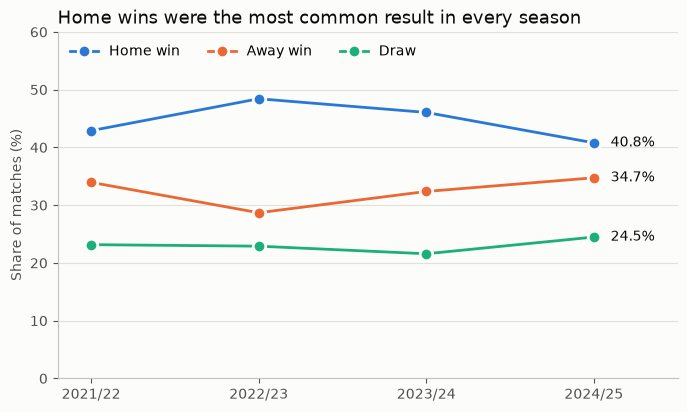

In [13]:
# Chart 1: Home advantage by season

# crosstab counts each result per season. normalize="index" turns counts into shares of each season.
result_share = pd.crosstab(matches["Season"], matches["FTR"], normalize="index") * 100
print(result_share.round(1))

fig, ax = plt.subplots()

# Draw one line per result: (column in the table, legend label, colour)
for result, label, colour in [("H", "Home win", BLUE), ("A", "Away win", ORANGE), ("D", "Draw", GREEN)]:
    values = result_share[result]
    ax.plot(values.index, values, label=label, color=colour, linewidth=2,
            marker="o", markersize=9, markeredgecolor=BACKGROUND, markeredgewidth=2)
    # Write the latest value just to the right of the final point
    ax.text(3.1, values.iloc[-1], f"{values.iloc[-1]:.1f}%", va="center", color=TEXT)

ax.set_title("Home wins were the most common result in every season")
ax.set_ylabel("Share of matches (%)")
ax.set_ylim(0, 60)            # Start at 0 so that differences aren't exaggerated
ax.set_xlim(-0.2, 3.5)        # Leave room for the labels on the right
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()

**Finding:** Home wins were the most common result in all four seasons, between 40.8% and 48.4%, so the model should treat home and away teams separately. The home win rate was lowest in 2024/25, which is the season we'll test on.

Average goals per match: 2.97
0     4.7
1    15.3
2    23.0
3    21.4
4    17.6
5    10.5
6     4.7
7     2.0
8     0.5
9     0.3
Name: proportion, dtype: float64


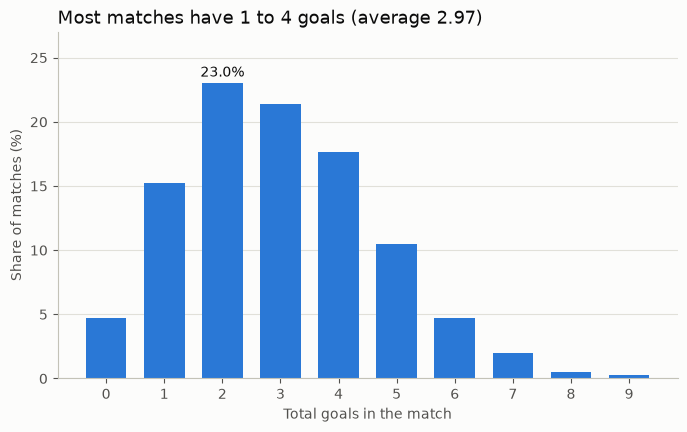

In [14]:
# Chart 2: Distribution of goals per match

total_goals = matches["FTHG"] + matches["FTAG"]

# value_counts counts how often each total occurs. normalize=True turns counts into shares.
goal_share = total_goals.value_counts(normalize=True).sort_index() * 100
print("Average goals per match:", round(total_goals.mean(), 2))
print(goal_share.round(1))

fig, ax = plt.subplots()
ax.bar(goal_share.index, goal_share.values, width=0.7, color=BLUE)

# Label only the tallest bar, because the y-axis covers the rest
most_common = goal_share.idxmax()
ax.text(most_common, goal_share.max() + 0.5, f"{goal_share.max():.1f}%", ha="center", color=TEXT)

ax.set_title(f"Most matches have 1 to 4 goals (average {total_goals.mean():.2f})")
ax.set_xlabel("Total goals in the match")
ax.set_ylabel("Share of matches (%)")
ax.set_xticks(goal_share.index)   # Show a tick for each goal total that occurred
ax.set_ylim(0, 27)                # Leave room for the label above the tallest bar
ax.grid(axis="x", visible=False)
plt.show()

**Finding:** About 77% of matches had between 1 and 4 goals, and 2 goals was the most common total (23.0%). Matches with 7 or more goals were rare, at about 3%. Goal counts bunch around a low average and tail off to the right, which is the kind of pattern a Poisson model is designed for.

                  Matches  Scored  Conceded
Team                                       
Man City              152    2.38      0.90
Liverpool             152    2.24      1.02
Arsenal               152    2.03      1.01
Tottenham             152    1.82      1.51
Newcastle             152    1.74      1.34
Chelsea               152    1.68      1.22
Aston Villa           152    1.56      1.39
Brighton              152    1.55      1.43
Brentford             152    1.50      1.47
Fulham                114    1.44      1.47
Man United            152    1.42      1.39
Luton                  38    1.37      2.24
West Ham              152    1.37      1.59
Bournemouth           114    1.31      1.61
Crystal Palace        152    1.30      1.34
Leicester             114    1.28      1.82
Nott'm Forest         114    1.27      1.59
Leeds                  76    1.18      2.07
Wolves                152    1.14      1.55
Everton               152    1.05      1.43
Burnley                76    0.9

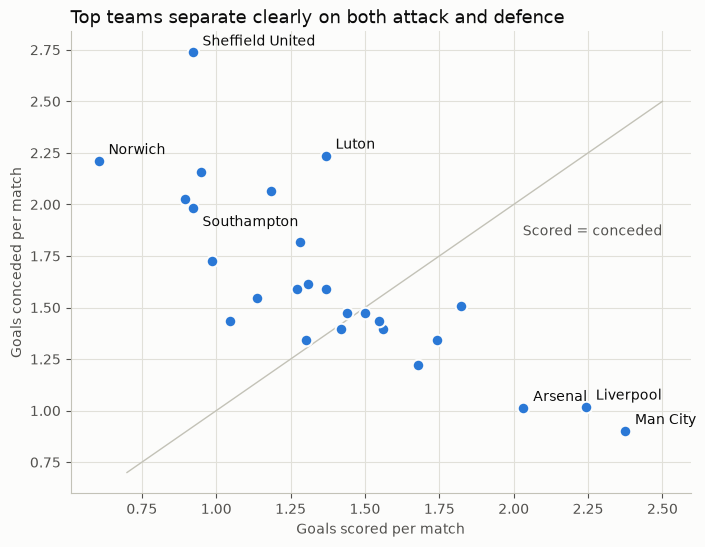

In [15]:
# Chart 3: Goals scored vs conceded by team

# Build one row per team per match, as in the SQL query, using a home view and an away view
home_view = matches[["HomeTeam", "FTHG", "FTAG"]].set_axis(["Team", "Scored", "Conceded"], axis=1)
away_view = matches[["AwayTeam", "FTAG", "FTHG"]].set_axis(["Team", "Scored", "Conceded"], axis=1)
team_view = pd.concat([home_view, away_view], ignore_index=True)

# Average per match, so that teams with fewer seasons can be compared fairly
team_stats = team_view.groupby("Team").agg(
    Matches=("Scored", "size"),
    Scored=("Scored", "mean"),
    Conceded=("Conceded", "mean"),
).sort_values("Scored", ascending=False)
print(team_stats.round(2))

fig, ax = plt.subplots(figsize=(8, 6))

# Teams on this line score as many as they concede. Teams below it score more.
ax.plot([0.7, 2.5], [0.7, 2.5], color=AXIS, linewidth=1)
ax.text(2.5, 1.85, "Scored = conceded", color=MUTED_TEXT, ha="right")

ax.scatter(team_stats["Scored"], team_stats["Conceded"], s=70, color=BLUE,
           edgecolors=BACKGROUND, linewidths=1.5, zorder=3)

# Label only the teams at the extremes, because 26 labels would be unreadable.
# Each label has its own position (in points from the dot) so that it doesn't cover a nearby dot.
labels = {
    "Man City": (7, 5),
    "Liverpool": (7, 5),
    "Arsenal": (7, 5),
    "Sheffield United": (7, 5),
    "Luton": (7, 5),
    "Norwich": (7, 5),
    "Southampton": (7, -13),
}
for team, offset in labels.items():
    ax.annotate(team, (team_stats.loc[team, "Scored"], team_stats.loc[team, "Conceded"]),
                xytext=offset, textcoords="offset points", color=TEXT)

ax.set_title("Top teams separate clearly on both attack and defence")
ax.set_xlabel("Goals scored per match")
ax.set_ylabel("Goals conceded per match")
plt.show()

**Finding:** Man City, Liverpool and Arsenal stand apart, scoring over 2 goals per match and conceding about 1. Attack and defence don't always go together: Tottenham scored 1.82 but conceded 1.51, while Crystal Palace scored 1.30 and conceded 1.34. That's why the model rates them separately. Some teams played only one season (38 matches), so their numbers are less reliable.

Matches with a clear favourite: 1502
Overall favourite win rate: 57.1
Season
2021/22    58.4
2022/23    56.4
2023/24    59.4
2024/25    54.3
dtype: float64


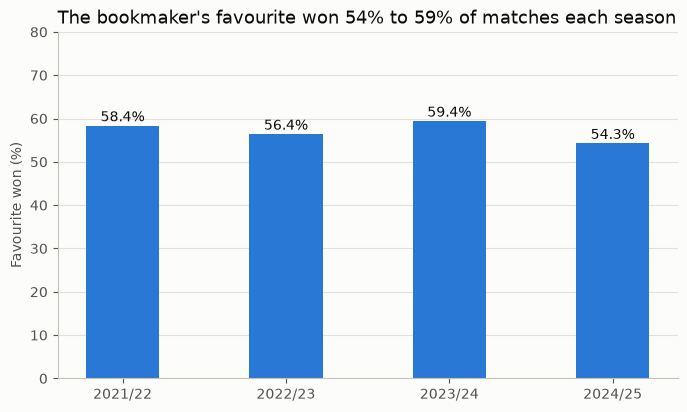

In [16]:
# Chart 4: How often the bookmaker's favourite won, by season

odds = matches[["B365H", "B365D", "B365A"]]

# A clear favourite means exactly one outcome has the lowest odds (the same rule as the SQL query)
has_clear_favourite = odds.eq(odds.min(axis=1), axis=0).sum(axis=1) == 1

# idxmin gives the column with the lowest odds, such as "B365H". The last letter is the result code.
favourite = odds.idxmin(axis=1).str[-1]

# Compare the favourite with the actual result, keeping only matches with a clear favourite
favourite_won = (favourite == matches["FTR"])[has_clear_favourite]

# The mean of True/False values is the share that are True
favourite_win_rate = favourite_won.groupby(matches["Season"]).mean() * 100
print("Matches with a clear favourite:", has_clear_favourite.sum())
print("Overall favourite win rate:", round(favourite_won.mean() * 100, 1))
print(favourite_win_rate.round(1))

fig, ax = plt.subplots()
ax.bar(favourite_win_rate.index, favourite_win_rate.values, width=0.45, color=BLUE)

# With only four bars, each one can carry its value
for season, rate in favourite_win_rate.items():
    ax.text(season, rate + 1, f"{rate:.1f}%", ha="center", color=TEXT)

ax.set_title("The bookmaker's favourite won 54% to 59% of matches each season")
ax.set_ylabel("Favourite won (%)")
ax.set_ylim(0, 80)            # Start at 0 so that differences aren't exaggerated
ax.grid(axis="x", visible=False)
plt.show()

**Finding:** The favourite won 57.1% of matches overall and stayed in a fairly narrow range, from 54.3% to 59.4%. So the favourite usually wins, but far from always. The rate was lowest in 2024/25, which suggests the test season may be a slightly harder one to predict.

## Step 5: Train/test split

The model learns from the first three seasons and is tested on 2024/25. We split by time rather than at random because a real forecast can only use the past. A random split would let the model learn from matches played after the ones it's predicting, which would make its results look better than they really are.

In [17]:
test_season = "2024/25"

# Each comparison gives True or False per row, and the table keeps only the True rows.
# .copy() makes each table independent, so later changes can't affect matches.
train = matches[matches["Season"] != test_season].copy()
test = matches[matches["Season"] == test_season].copy()

# Check 1: the two tables together should contain every match
print("Training matches:", len(train))
print("Test matches:", len(test))
print("Total:", len(train) + len(test), "out of", len(matches))

# Check 2: all training matches should be played before the first test match
print("\nTraining dates:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test dates:", test["Date"].min().date(), "to", test["Date"].max().date())
print("Training ends before testing starts:", train["Date"].max() < test["Date"].min())

# Check 3: which test season teams never appear in the training data?
train_teams = set(train["HomeTeam"]) | set(train["AwayTeam"])
test_teams = set(test["HomeTeam"]) | set(test["AwayTeam"])
new_teams = sorted(test_teams - train_teams)   # Teams in test but not in training
print("\nTest season teams with no training data:", new_teams)

# Count the test matches affected. The model can't rate these teams, so step 9 will skip them.
involves_new_team = test["HomeTeam"].isin(new_teams) | test["AwayTeam"].isin(new_teams)
print("Test matches involving those teams:", involves_new_team.sum())
print("Test matches the model can predict:", (~involves_new_team).sum())

Training matches: 1140
Test matches: 380
Total: 1520 out of 1520

Training dates: 2021-08-13 to 2024-05-19
Test dates: 2024-08-16 to 2025-05-25
Training ends before testing starts: True

Test season teams with no training data: ['Ipswich']
Test matches involving those teams: 38
Test matches the model can predict: 342
